# Apoio à triagem de lesões de pele com um único modelo

**Projeto Final – InsperAI · Felipe Gava e Lucas Briones**

## Problema
O câncer de pele é o tipo de câncer mais comum, e o melanoma, embora menos frequente, é o mais letal. Quando é detectado cedo, a cura é muito mais provável. O exame de rotina do dermatologista é a **dermatoscopia**: uma lente com iluminação que mostra estruturas da pele invisíveis a olho nu. Interpretar essas imagens exige experiência, e mesmo especialistas erram uma parte relevante dos casos. O diagnóstico definitivo só vem da biópsia (histopatologia).

## Objetivo
Indicar, a partir de uma foto da lesão, o **tipo da lesão** entre 8 classes e se ela merece avaliação médica. O sistema aceita **foto de celular** e **imagem de dermatoscopia**, com **um único modelo de pintas** nas duas:

| Classe | Lesão | Maligna? |
|---|---|---|
| `mel` | melanoma | sim |
| `bcc` | carcinoma basocelular | sim |
| `scc` | carcinoma espinocelular | sim |
| `ak` | ceratose actínica (pré-cancerígena) | sim* |
| `nv` | nevo melanocítico ("pinta" comum) | não |
| `bkl` | lesão benigna tipo ceratose | não |
| `df` | dermatofibroma | não |
| `vasc` | lesão vascular | não |

\* lesão pré-maligna, agrupada com as malignas na triagem.

O resultado é sempre uma **sugestão ou orientação, nunca um diagnóstico**.

## Abordagem
A ideia central é ensinar a rede a reconhecer lesões em foto de celular **sem usar nenhuma foto de celular no treino**:

1. **Pesos de partida**: EfficientNetV2-B0 (224 px, com idade, sexo e região do corpo) ajustada no ISIC 2019.
2. **Fotos clínicas comuns** entram no treino, junto com mais dermatoscopia (ISIC 2020, MILK10k, MED-NODE, MSKCC).
3. **Augmentation que simula celular** (`pipeline.simular_celular`): resolução baixa, desfoque, ruído, JPEG, balanço de branco, sombra, lesão mais longe.
4. **Teste em fotos reais de celular** (PAD-UFES-20 e HIBA), que nunca entram no treino, e em dermatoscopia (ISIC 2018).

## Métrica
A base é muito desbalanceada: cerca de metade das imagens são nevos benignos. Um modelo que respondesse sempre "nevo" teria ~50% de acurácia sem servir para nada. Por isso a métrica principal é a **acurácia balanceada**, a média da sensibilidade de cada classe e métrica oficial do desafio ISIC. A acurácia comum também é reportada.

## Estrutura
1. **Dados**: a base, as classes, as origens e a composição do treino.
2. **Modelo**: como foi construído, a simulação de celular e as curvas de treino.
3. **Teste em dermatoscopia**: ISIC 2018, triagem maligno/benigno e dermatologistas.
4. **Teste em fotos de celular**: PAD-UFES-20 e HIBA.
5. **Registro de iterações**: o que foi testado em cada rodada e os resultados.

A triagem de erupções, alergias e queimaduras está pausada e separada em `triagem_alergias/`.


In [1]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, HAM_CLASSES, load_labels
import sys

from pipeline import CLASS_IDX, HAM_IDX, augment, build_cache, center_crop, decode, make_ds, simular_celular

sys.path.insert(0, "scripts")  # treinar_simulando_celular.py, para remontar a composição do treino

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026101904


GPUs: []


# 1. Dados

O modelo foi treinado com bases públicas de dermatoscopia e de fotos clínicas, harmonizadas nas mesmas 8 classes:

- **Treino e validação**: ISIC 2019 (HAM10000, BCN_20000, MSK), ISIC 2020, MILK10k (dermatoscopia e *close-up*), MED-NODE, MSKCC e fotos anônimas do acervo ISIC. A separação é **por paciente/lesão**, para que imagens da mesma lesão nunca fiquem nos dois lados. Os nevos são limitados a 6.000.
- **Teste em dermatoscopia: ISIC 2018 Task 3**, 1.511 imagens, rotuladas nas 7 classes do HAM10000 (`akiec` junta `ak` e `scc`).
- **Teste em celular: PAD-UFES-20 e HIBA inteiras**, 2.643 fotos, que nunca entram no treino nem na validação.

As imagens da base ampliada somam ~54 GB e ficam fora do repositório. Vão para o git os scripts que as baixam e o **manifesto** (`data/processed/manifesto.csv.gz`). Por isso o treino não roda em qualquer PC, mas a composição dos conjuntos e toda a avaliação, sim: vêm do manifesto e das previsões salvas. Abaixo exploramos primeiro o ISIC 2019, a maior parte do treino, cujas imagens estão neste PC.

In [3]:
# Base única gerada pelo prepare_data.py (ver README):
# train/val = ISIC 2019 (HAM10000 + BCN_20000 + MSK), 8 classes
# test      = ISIC 2018 Task 3, rotulado só nas 7 classes do HAM (coluna dx_ham)
# unlabeled = resto do teste do ISIC 2019, sem rótulo
df = load_labels()
train_df, val_df, test_df, unlabeled_df = (
    df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test", "unlabeled"]
)
print({s: len(d) for s, d in zip(["train", "val", "test", "unlabeled"],
                                 [train_df, val_df, test_df, unlabeled_df])})
df.head()

{'train': 21486, 'val': 3845, 'test': 1511, 'unlabeled': 6726}


,image_id,file_id,lesion_id,split,dx,dx_ham,dx_name,malignant,source,dataset,dx_type,age_approx,sex,site,image_path,mask_path
0,ISIC_0000000,ISIC_0000000,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,55.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
1,ISIC_0000001,ISIC_0000001,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
2,ISIC_0000002,ISIC_0000002,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,60.0,female,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN
3,ISIC_0000003,ISIC_0000003,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,male,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
4,ISIC_0000004,ISIC_0000004,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,80.0,male,posterior torso,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN


In [4]:
# Classes por split (no teste, o rótulo disponível é o dx_ham: akiec = ak + scc)
labeled = df[df["split"] != "unlabeled"]
pd.crosstab(labeled["dx"].fillna(labeled["dx_ham"]), labeled["split"], margins=True)

split,test,train,val,All
dx,,,,
ak,0,719,148,867
akiec,43,0,0,43
bcc,93,2824,499,3416
bkl,217,2251,373,2841
df,44,200,39,283
mel,171,3855,667,4693
nv,908,10893,1982,13783
scc,0,533,95,628
vasc,35,211,42,288


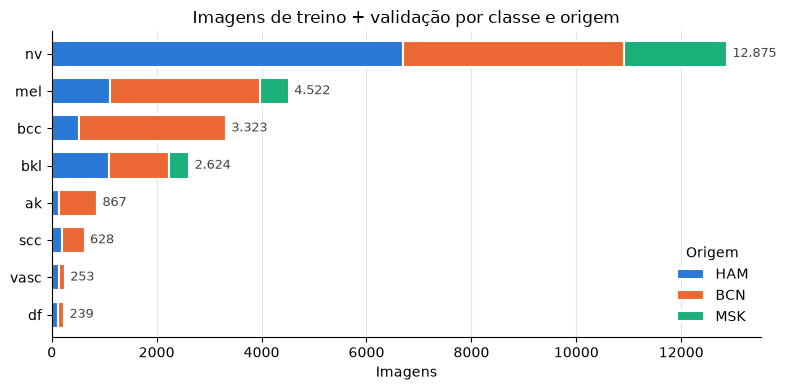

dx,ak,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,
HAM,1.3,5.1,11.0,1.1,11.1,66.9,2.0,1.4
BCN,5.9,22.6,9.2,1.0,23.0,33.9,3.5,0.9
MSK,0.0,0.0,13.3,0.0,19.0,67.7,0.0,0.0


In [5]:
# Treino + validação por classe e origem
SOURCES = ["HAM", "BCN", "MSK"]
SOURCE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

trainval = df[df["split"].isin(["train", "val"])]
counts = pd.crosstab(trainval["dx"], trainval["source"])[SOURCES]
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(stacked=True, color=SOURCE_COLORS, edgecolor="white", linewidth=1.5, width=0.7, ax=ax)
for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 100, i, f"{total:,}".replace(",", "."), va="center", fontsize=9, color="#444")
ax.set(xlabel="Imagens", ylabel="", title="Imagens de treino + validação por classe e origem")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(title="Origem", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Proporção (%) de cada classe dentro de cada origem
display((pd.crosstab(trainval["source"], trainval["dx"], normalize="index") * 100).round(1).loc[SOURCES, CLASSES])

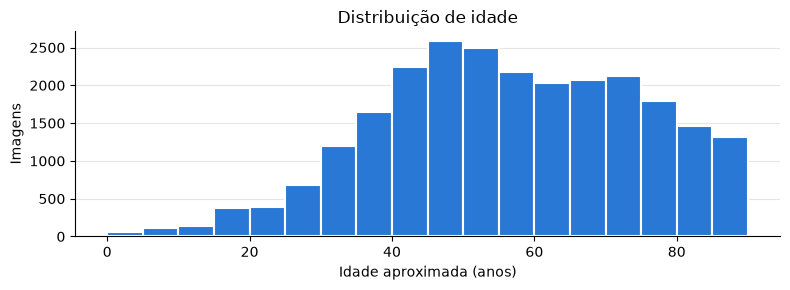

Faltantes (%):
age_approx     1.7
sex            1.5
site          10.2


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
site,,,,,,,,
(vazio),22,72,273,3,127,2049,6,31
anterior torso,92,1114,445,43,1331,3699,113,78
head/neck,598,1131,1001,0,880,767,174,36
lateral torso,0,0,6,0,14,34,0,0
lower extremity,66,462,412,138,796,2876,182,58
oral/genital,0,0,16,1,19,69,0,2
palms/soles,6,0,7,0,201,168,13,3
posterior torso,4,186,230,2,430,1888,25,22
upper extremity,79,358,234,52,724,1325,115,23


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
sex,,,,,,,,
(vazio),3,6,23,0,81,271,0,0
female,406,1317,1134,117,1980,6379,203,125
male,458,2000,1467,122,2461,6225,425,128


In [6]:
# Metadados clínicos (treino + validação)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(trainval["age_approx"].dropna(), bins=np.arange(0, 95, 5), color="#2a78d6", edgecolor="white", linewidth=1.5)
ax.set(xlabel="Idade aproximada (anos)", ylabel="Imagens", title="Distribuição de idade")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Faltantes (%):")
print((trainval[["age_approx", "sex", "site"]].isna().mean() * 100).round(1).to_string())
display(pd.crosstab(trainval["site"].fillna("(vazio)"), trainval["dx"])[CLASSES])
display(pd.crosstab(trainval["sex"].fillna("(vazio)"), trainval["dx"])[CLASSES])

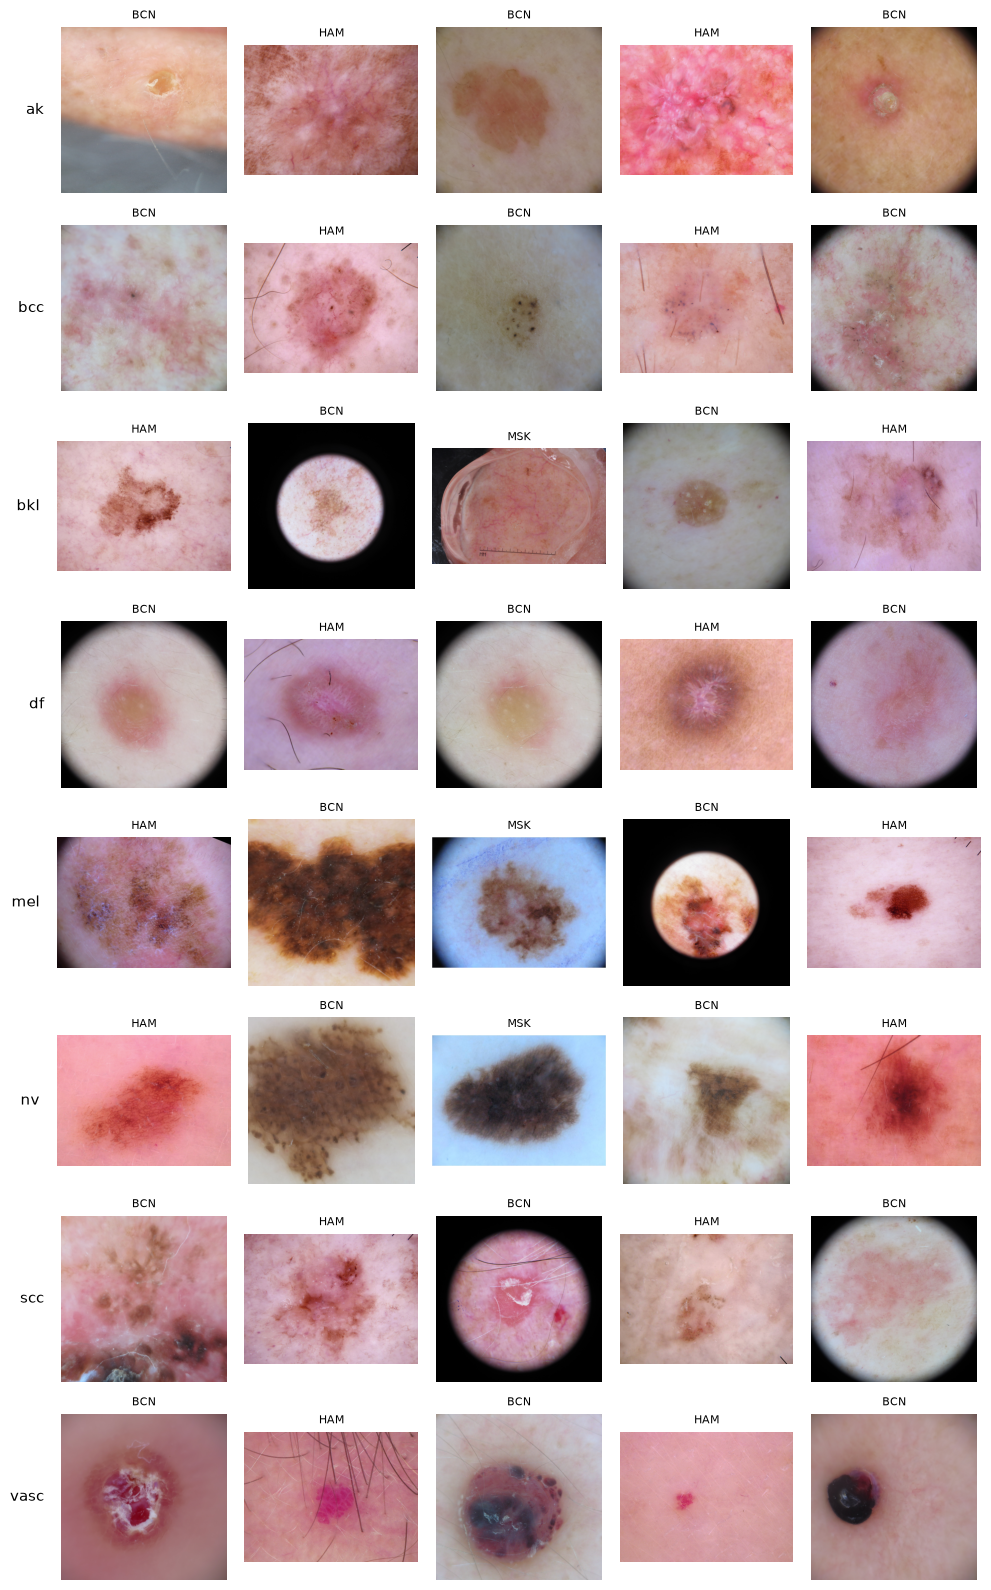

source
BCN                                   {(1024, 1024): 50}
HAM                                     {(600, 450): 50}
MSK    {(1024, 680): 19, (1024, 768): 10, (1024, 685)...
Name: size, dtype: object

In [7]:
# Exemplos de cada classe, misturando as origens
N_EXAMPLES = 5
fig, axes = plt.subplots(len(CLASSES), N_EXAMPLES, figsize=(2 * N_EXAMPLES, 2 * len(CLASSES)))
for row, dx in zip(axes, CLASSES):
    pool = train_df[train_df["dx"] == dx].groupby("source").head(N_EXAMPLES)
    sample = pool.sample(min(N_EXAMPLES, len(pool)), random_state=SEED)
    for ax in row:
        ax.axis("off")
    for ax, r in zip(row, sample.itertuples()):
        ax.imshow(Image.open(r.image_path))
        ax.set_title(r.source, fontsize=8)
    row[0].text(-0.1, 0.5, dx, transform=row[0].transAxes, ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

# Tamanho das imagens por origem (amostra)
sizes = train_df.groupby("source").sample(50, random_state=SEED)
sizes["size"] = [Image.open(p).size for p in sizes["image_path"]]
sizes.groupby("source")["size"].agg(lambda s: s.value_counts().head(3).to_dict())

## Composição do treino, da validação e do teste

In [8]:
# Remonta os conjuntos usando o mesmo código do treino, a partir do manifesto do repositório
from treinar_simulando_celular import CONJUNTOS, montar_tabela

treino_modelo, val_modelo, teste_celular = montar_tabela(CONJUNTOS["dermatoscopia+fotos"], max_nevos=6000, rapido=False)
conjuntos = pd.concat({"treino": treino_modelo, "validação": val_modelo, "teste celular": teste_celular}, names=["conjunto"]).reset_index("conjunto").reset_index(drop=True)
display(pd.crosstab(conjuntos["grupo"], conjuntos["conjunto"], margins=True)[["treino", "validação", "teste celular", "All"]])
pd.crosstab(conjuntos["dx"], conjuntos["conjunto"], margins=True)[["treino", "validação", "teste celular", "All"]]

conjunto,treino,validação,teste celular,All
grupo,,,,
anonima,69,14,0,83
hiba,0,0,345,345
isic2019_train,14813,3801,0,18614
isic2020,1921,901,0,2822
mednode,81,24,0,105
milk10k_dermatoscopia,3264,770,0,4034
milk10k_foto,3261,770,0,4031
mskcc,26,5,0,31
pad_ufes_20,0,0,2298,2298


conjunto,treino,validação,teste celular,All
dx,,,,
ak,910,165,747,1822
bcc,6384,1260,959,8603
bkl,3145,592,261,3998
df,275,50,22,347
mel,4981,914,117,6012
nv,6000,2955,297,9252
scc,1460,296,240,1996
vasc,280,53,0,333
All,23435,6285,2643,32363


# 2. Modelo

## Como o modelo foi construído

Uma única rede: **EfficientNetV2-B0 em 224 px** mais uma segunda entrada com 14 metadados (idade, sexo, região do corpo, com indicadores de faltante) e 8 saídas (logits). A construção teve duas etapas.

**Etapa 1: pesos de partida** (`modelos/pintas/pesos_de_partida.keras`). Transfer learning do ImageNet no treino do ISIC 2019 (21.486 imagens): primeiro só a cabeça, depois o ajuste fino da rede inteira com as BatchNormalization congeladas, AdamW (lr de pico 3e-4, weight decay 0,02), aquecimento + cosseno e parada antecipada. Pré-processamento com **Shades of Gray**, que uniformiza a cor entre aparelhos, e augmentation geométrica e de cor (`pipeline.augment`). Esses pesos não são mais um modelo do projeto, só o ponto de partida: em foto de celular eles desabam (AUC de melanoma 0,59).

**Etapa 2: adaptação para o celular** (`scripts/treinar_simulando_celular.py --conjunto dermatoscopia+fotos`), o que produz o modelo final (`modelos/pintas/melhor.keras`):

- **Treino**: 23.435 imagens sem nenhuma foto de celular, incluindo fotos clínicas de câmera. **Validação**: 6.285 imagens das mesmas fontes, que decide a época, o `tau` e o limiar.
- **Augmentation**: a do pipeline **mais** a simulação de celular (abaixo).
- **Otimização**: toda a rede treinável exceto BatchNormalization, AdamW (wd 0,02), lr 1e-4 com 1 época de aquecimento e cosseno, lote 32, até 8 épocas com parada antecipada (paciência 3). Melhor época: 7. Cerca de 2,5 h na CPU.
- **Decisão**: TTA de 8 vistas (4 rotações × espelhamento); ajuste de prior `log p − tau·log prior` com **tau = 1,1**; triagem pela soma de p(ak, bcc, mel, scc) ≥ **0,287**, o limiar de 95% de sensibilidade na validação.

**O que cada ingrediente rendeu** (no teste de celular):

| Variante | AUC melanoma | Acurácia balanceada |
|---|---|---|
| Pesos de partida | 0,593 | 30% |
| Só dermatoscopia + simulação | 0,735 | 40% |
| Dermatoscopia + fotos clínicas, sem simulação | 0,827 | 46% |
| **Dermatoscopia + fotos clínicas + simulação (final)** | **0,871** | **48%** |

A maior parte do ganho vem de pôr **fotos clínicas comuns** no treino; a simulação soma mais +0,044 de AUC por cima.

Para retreinar é preciso a base ampliada (ver README): `uv run scripts/treinar_simulando_celular.py --conjunto dermatoscopia+fotos`.

In [9]:
PASTA_MODELO = Path("modelos/pintas")
IMG_SIZE, BATCH_SIZE, TTA_VIEWS, CACHE_SIZE = 224, 32, 8, 288
CACHE_DIR = Path(os.environ.get("CACHE_DIR", DEFAULT_DIR.parent / f"lesoes_pele_cache_{CACHE_SIZE}"))

# Parâmetros de decisão, escolhidos na validação do treino (nenhuma imagem de teste)
PRIOR = np.array([910, 6384, 3145, 275, 4981, 6000, 1460, 280], dtype=float)  # classes no treino, ordem de CLASSES
LOG_PRIOR = np.log(PRIOR / PRIOR.sum())
TAU, LIMIAR_MALIGNO = 1.1, 0.287

rede_pintas = keras.models.load_model(PASTA_MODELO / "melhor.keras", compile=False)
print({k: tuple(v.shape) for k, v in zip(["image", "meta"], rede_pintas.inputs)}, "->", tuple(rede_pintas.output.shape))
print(f"{rede_pintas.count_params():,} parâmetros | tau {TAU} | limiar de triagem {LIMIAR_MALIGNO}")

{'image': (None, 224, 224, 3), 'meta': (None, 14)} -> (None, 8)
5,931,288 parâmetros | tau 1.1 | limiar de triagem 0.287


## A simulação de celular

`pipeline.simular_celular` é aplicada depois da augmentation comum, sorteando cada efeito por imagem:

| Ordem | Efeito | Chance | O que imita |
|---|---|---|---|
| 1 | recorte interno (70–90%) | 50% | tira a borda do dermatoscópio |
| 2 | afastar (lesão em 50–90% do quadro) | 40% | foto de mais longe |
| 3 | brilho, contraste, saturação e matiz fortes | 60% | luz ruim |
| 4 | balanço de branco (0,8–1,2 por canal) | 50% | luz amarela ou azulada |
| 5 | sombra em gradiente | 40% | sombra da mão, luz lateral |
| 6 | perda de resolução (25–70%) | 50% | sensor fraco, foto de longe |
| 7 | desfoque gaussiano (sigma 0,5–2,5) | 40% | foco ruim |
| 8 | ruído de sensor (sigma 3–14) | 50% | pouca luz |
| 9 | recompressão JPEG (qualidade 25–80) | 50% | WhatsApp e apps |

A célula seguinte executa o código de verdade em imagens do treino: na 1ª linha a original, nas outras duas sorteios da augmentation.

**Limitações observadas**: o fundo do efeito "afastar" sai como um retângulo acinzentado com borda marcada, que não lembra uma foto real; a augmentation comum ainda desenha a borda do dermatoscópio em 25% das imagens, o oposto do que se quer simular; e em alguns sorteios a lesão quase some, mantendo o rótulo. Corrigir isso exige retreinar, por isso fica nos próximos passos.

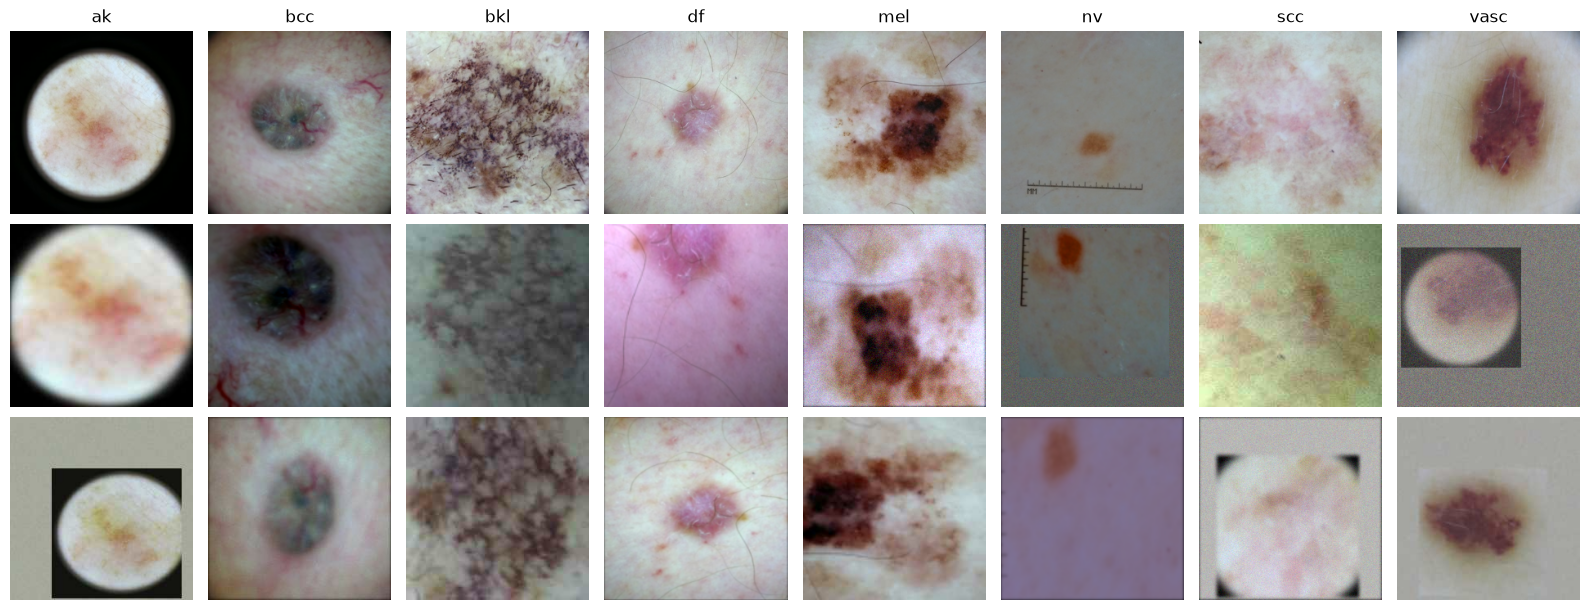

In [10]:
amostra = build_cache(train_df.groupby("dx").sample(1, random_state=SEED), CACHE_DIR, size=CACHE_SIZE)
keras.utils.set_random_seed(SEED)

fig, axes = plt.subplots(3, 8, figsize=(16, 6.2))
for j, (caminho, dx) in enumerate(zip(amostra["image_path"], amostra["dx"])):
    img = decode(caminho)
    axes[0, j].imshow(center_crop(img, IMG_SIZE).numpy().astype("uint8"))
    axes[0, j].set_title(dx)
    for i in (1, 2):
        axes[i, j].imshow(simular_celular(augment(img, IMG_SIZE), IMG_SIZE).numpy().astype("uint8"))
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

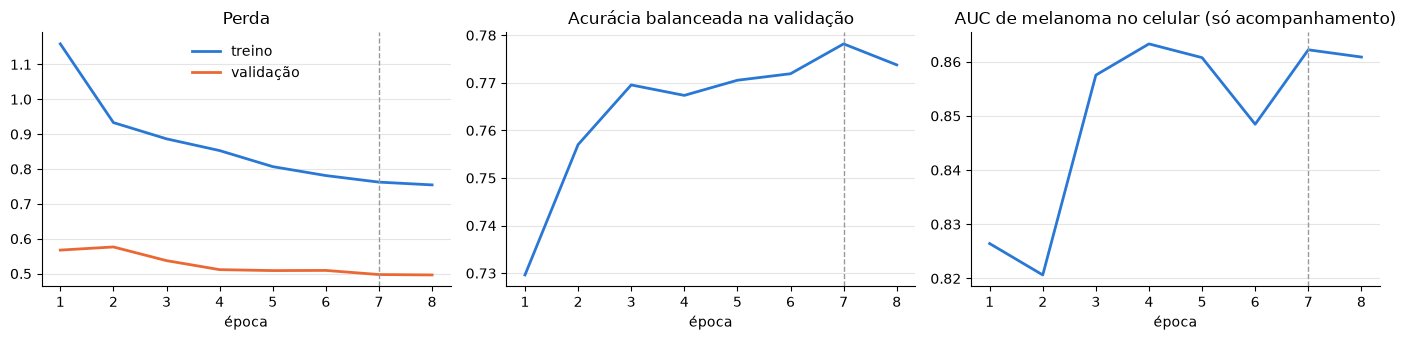

Melhor época (acurácia balanceada na validação): 7


In [11]:
# Curvas da etapa 2. A AUC no celular só era acompanhada: nunca escolheu época nem parâmetro
h = pd.read_csv(PASTA_MODELO / "historico.csv")
epoca = h["epoch"] + 1
melhor = epoca[h["val_bal_acc"].idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(epoca, h["loss"], color="#2a78d6", lw=2, label="treino")
axes[0].plot(epoca, h["val_loss"], color="#eb6834", lw=2, label="validação")
axes[0].set(title="Perda", xlabel="época")
axes[0].legend(frameon=False)
axes[1].plot(epoca, h["val_bal_acc"], color="#2a78d6", lw=2)
axes[1].set(title="Acurácia balanceada na validação", xlabel="época")
axes[2].plot(epoca, h["celular_mel_auc_informativo"], color="#2a78d6", lw=2)
axes[2].set(title="AUC de melanoma no celular (só acompanhamento)", xlabel="época")
for a in axes:
    a.axvline(melhor, color="#999", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e5e5e5")
plt.tight_layout()
plt.show()
print("Melhor época (acurácia balanceada na validação):", int(melhor))

# 3. Teste em dermatoscopia

Avaliação no **teste do ISIC 2018** (1.511 imagens, 7 classes), com TTA de 8 vistas. Nenhuma dessas imagens entra no treino nem na validação. `tau` e limiar vêm da validação do treino e foram aplicados aqui sem ajuste.

- **Métricas gerais e comparação com os pesos de partida.**
- **Relatório por classe e matriz de confusão.**
- **Triagem maligno × benigno** e a troca entre sensibilidade e especificidade.
- **Dermatologistas**: as mesmas imagens foram diagnosticadas por centenas de médicos (Tschandl et al., *Nature Medicine* 2020).
- **Uso do modelo salvo.**

In [12]:
MALIGNANT_8 = [CLASS_IDX[c] for c in ["ak", "bcc", "mel", "scc"]]
MALIGNANT_7 = [HAM_IDX[c] for c in ["akiec", "bcc", "mel"]]


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def adjust(p, tau=TAU):
    """Ajuste de logits: divide as probabilidades por prior**tau e renormaliza."""
    return softmax(np.log(p + 1e-12) - tau * LOG_PRIOR)


def to_ham(p):
    """8 classes -> 7 do HAM10000 (akiec = ak + scc), para comparar com o gabarito do teste."""
    return np.stack([p[:, CLASS_IDX["ak"]] + p[:, CLASS_IDX["scc"]] if c == "akiec" else p[:, CLASS_IDX[c]]
                     for c in HAM_CLASSES], axis=1)


salvos = np.load(PASTA_MODELO / "probs_isic2018.npz")
teste = df[df["split"] == "test"].set_index("file_id").loc[salvos["ids_test"].astype(str)].reset_index()
y_test = teste["dx_ham"].map(HAM_IDX).values
raw, ajustada = to_ham(salvos["test"]), to_ham(adjust(salvos["test"]))
pred = ajustada.argmax(1)

# Métricas do modelo recalculadas aqui; os pesos de partida vêm do CSV da comparação
comparacao = pd.read_csv(PASTA_MODELO / "comparacao_dermatoscopia.csv").set_index("modelo")
recalculado = {"acuracia": accuracy_score(y_test, raw.argmax(1)), "acuracia_balanceada": balanced_accuracy_score(y_test, pred),
               "auc_macro": roc_auc_score(y_test, raw, multi_class="ovr", labels=range(len(HAM_CLASSES))),
               "maligno_auc": roc_auc_score(np.isin(y_test, MALIGNANT_7), raw[:, MALIGNANT_7].sum(1))}
for k, v in recalculado.items():
    assert abs(comparacao.loc["modelo do projeto (simulação de celular)", k] - v) < 1e-9, k
comparacao.T.round(3)

modelo,pesos de partida (só ISIC 2019),modelo do projeto (simulação de celular)
imagens,1511.000,1511.000
melanomas,171.000,171.000
tau,0.900,1.100
limiar,0.045,0.287
acuracia,0.822,0.828
acuracia_balanceada,0.743,0.750
auc_macro,0.961,0.966
mel_auc,0.928,0.931
maligno_auc,0.943,0.945
mel_sensibilidade,0.503,0.620


**Resultado.** Na dermatoscopia o modelo **empata** com os pesos de partida: as diferenças ficam dentro do ruído (IC 95% por bootstrap: acurácia −1,1 a +2,3 pontos; acurácia balanceada −2,4 a +3,6 pontos; AUC maligno × benigno −0,006 a +0,012). Ganhou o celular sem perder a dermatoscopia.

O que muda é o **ponto de operação**: a sensibilidade de melanoma como classe sobe de 50% para 62%, mas a triagem deixa passar mais malignos (26 contra 13 de 307), em troca de 10 pontos a mais de especificidade. Veja a tabela de limiares abaixo.

              precision    recall  f1-score   support

       akiec      0.449     0.721     0.554        43
         bcc      0.795     0.667     0.725        93
         bkl      0.770     0.631     0.694       217
          df      0.473     0.795     0.593        44
         mel      0.582     0.620     0.601       171
          nv      0.927     0.903     0.915       908
        vasc      0.711     0.914     0.800        35

    accuracy                          0.809      1511
   macro avg      0.672     0.750     0.697      1511
weighted avg      0.825     0.809     0.813      1511



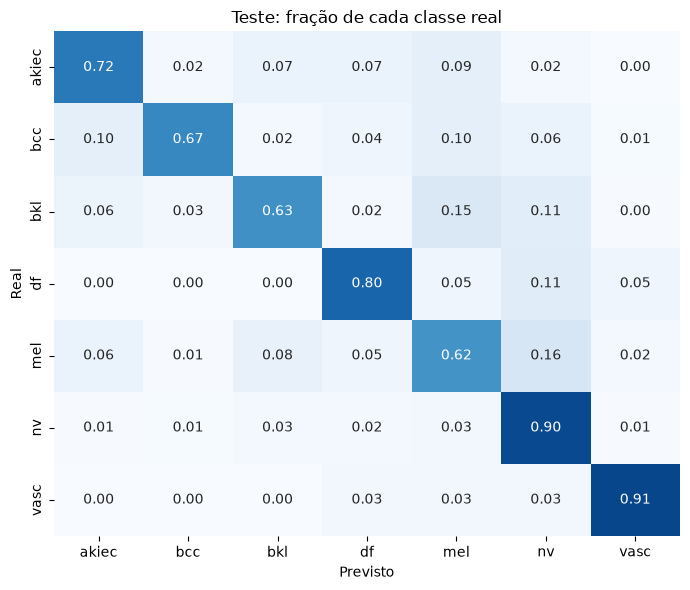

In [13]:
# Relatório por classe e matriz de confusão (decisão ajustada pelo prior)
labels = list(range(len(HAM_CLASSES)))
print(classification_report(y_test, pred, labels=labels, target_names=HAM_CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=HAM_CLASSES, yticklabels=HAM_CLASSES, ax=ax)
ax.set(xlabel="Previsto", ylabel="Real", title="Teste: fração de cada classe real")
plt.tight_layout()
plt.show()

In [14]:
# Triagem "maligno ou não" (mel, bcc, akiec). O limiar vem da validação; a tabela mostra a troca
# entre sensibilidade e especificidade. A validação aqui é a parte só de dermatoscopia (ISIC 2019).
val_salva = np.load(PASTA_MODELO / "probs_val_dermatoscopia.npz")
y_val = np.array([CLASS_IDX[d] for d in val_salva["dx_val"].astype(str)])
score_val, mal_val = val_salva["val"][:, MALIGNANT_8].sum(1), np.isin(y_val, MALIGNANT_8)
score_test, mal_test = raw[:, MALIGNANT_7].sum(1), np.isin(y_test, MALIGNANT_7)

linhas = []
for limiar in [0.10, 0.15, 0.20, LIMIAR_MALIGNO, 0.40, 0.50]:
    linhas.append({"limiar": limiar, "sensibilidade (validação)": (score_val[mal_val] >= limiar).mean(),
                   "sensibilidade (teste)": (score_test[mal_test] >= limiar).mean(),
                   "especificidade (teste)": (score_test[~mal_test] < limiar).mean(),
                   "malignas perdidas (teste)": int((score_test[mal_test] < limiar).sum())})
print(f"AUC maligno x benigno no teste: {roc_auc_score(mal_test, score_test):.3f}")
pd.DataFrame(linhas).set_index("limiar").round(3)

AUC maligno x benigno no teste: 0.945


,sensibilidade (validação),sensibilidade (teste),especificidade (teste),malignas perdidas (teste)
limiar,,,,
0.100,0.994,0.990,0.648,3
0.150,0.986,0.971,0.699,9
0.200,0.975,0.948,0.760,16
0.287,0.958,0.915,0.832,26
0.400,0.922,0.844,0.885,48
0.500,0.880,0.788,0.924,65


O limiar **0,287** dá 95,8% de sensibilidade na validação, mas 91,5% no teste: a queda vem da mudança de base (o teste é todo HAM10000), e não do limiar. Recalcular o limiar só em dermatoscopia não ajudou (0,314, sensibilidade de 89,6% no teste). Limiares mais baixos da tabela sobem a sensibilidade à custa de especificidade; essa escolha não foi feita olhando o teste, e por isso o 0,287 foi mantido.

In [15]:
# Dermatologistas nas mesmas imagens do teste (Tschandl et al., Nature Medicine 2020): cada
# linha do CSV é um diagnóstico de um médico, sem e com o apoio da IA daquele estudo.
READERS_CSV = Path(os.environ.get(
    "READERS_CSV",
    Path.cwd().parent / "dataverse_files" / "ISIC2018_Task3_Test_NatureMedicine_AI_Interaction_Benefit.csv"))
if READERS_CSV.exists():
    nm = pd.read_csv(READERS_CSV, decimal=",")
    truth = teste.set_index("image_id")["dx_ham"].map(HAM_IDX)
    nm = nm[nm["image_id"].isin(truth.index)]
    y_nm = nm["image_id"].map(truth).values
    ours = pd.Series(pred, index=teste["image_id"].values)

    def answers(prefix):
        return nm[[f"{prefix}_{c}" for c in HAM_CLASSES]].values.argmax(1)

    comp = {
        "Dermatologistas sem IA": answers("user_dx_without_interaction"),
        "Dermatologistas com a IA do estudo": answers("user_dx_with_interaction"),
        "IA do estudo": answers("prob_m_dx"),
        "Nosso modelo": nm["image_id"].map(ours).values,
    }
    print(f"{len(nm)} diagnósticos em {nm['image_id'].nunique()} imagens do teste")
    display(pd.DataFrame({k: {"acurácia": accuracy_score(y_nm, v),
                              "acurácia balanceada": balanced_accuracy_score(y_nm, v)}
                          for k, v in comp.items()}).T.round(3))
else:
    print("CSV dos dermatologistas não encontrado:", READERS_CSV)

3762 diagnósticos em 1412 imagens do teste


,acurácia,acurácia balanceada
Dermatologistas sem IA,0.694,0.714
Dermatologistas com a IA do estudo,0.744,0.754
IA do estudo,0.782,0.777
Nosso modelo,0.763,0.750


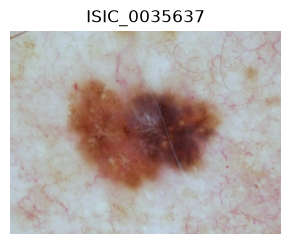

Diagnóstico real: Melanoma
Classes mais prováveis:
  Melanoma                          93.1%
  Nevo melanocítico                  6.2%
  Dermatofibroma                     0.3%
Triagem: probabilidade de malignidade 92.4% (limiar 28.7%) -> SUSPEITA, encaminhar para avaliação


In [16]:
# Usando o modelo salvo: classifica uma imagem do teste (aqui, um melanoma), como seria na prática
def view_tta(x, k):
    img = tf.image.rot90(x["image"], k % 4)
    return {**x, "image": tf.image.flip_left_right(img) if k >= 4 else img}


def predict_tta(model, data, views=TTA_VIEWS):
    ds = make_ds(data, IMG_SIZE, BATCH_SIZE, labels=None, use_meta=True)
    return sum(softmax(model.predict(ds.map(lambda x, k=k: view_tta(x, k)), verbose=0)) for k in range(views)) / views


exemplo = build_cache(teste[teste["dx_ham"] == "mel"].sample(1, random_state=SEED), CACHE_DIR, size=CACHE_SIZE)
p = predict_tta(rede_pintas, exemplo)
p_adj = adjust(p)[0]
score = p[0, MALIGNANT_8].sum()

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(Image.open(exemplo["image_path"].iloc[0]))
ax.set_title(exemplo["file_id"].iloc[0])
ax.axis("off")
plt.show()

print("Diagnóstico real:", DX_NAMES[exemplo["dx_ham"].iloc[0]])
print("Classes mais prováveis:")
for i in np.argsort(p_adj)[::-1][:3]:
    print(f"  {DX_NAMES[CLASSES[i]]:<32} {p_adj[i]:6.1%}")
print(f"Triagem: probabilidade de malignidade {score:.1%} (limiar {LIMIAR_MALIGNO:.1%}) ->",
      "SUSPEITA, encaminhar para avaliação" if score >= LIMIAR_MALIGNO else "baixa suspeita")

# 4. Teste em fotos de celular

O uso final começa por uma **foto de celular**, sem lente. A lente do dermatoscópio dá textura fina, cor calibrada e borda preta; o celular tem foco ruim, ruído, compressão, sombra e balanço de branco errado. Por isso os pesos de partida, ajustados só em dermatoscopia, desabam aqui.

O teste são as duas bases públicas com celular confirmado, **PAD-UFES-20** (Brasil, 2.298 fotos) e **HIBA** (Argentina, 345 fotos), usadas inteiras: 2.643 fotos, 117 melanomas, medidas com TTA. Tudo abaixo é lido das previsões salvas em `modelos/pintas/previsoes_celular.csv`.

**Cuidado na leitura:** as três variantes de treino da tabela da seção 2 foram comparadas neste mesmo teste, e a melhor foi a escolhida. Época, `tau` e limiar vieram só da validação, mas a escolha da variante viu o teste, então o resultado pode estar levemente otimista.

In [17]:
comp = pd.read_csv(PASTA_MODELO / "comparacao.csv")
comp["modelo"] = comp["modelo"].str.replace("antes (Felipe)", "pesos de partida", regex=False).str.replace("depois (B_dermatoscopia+fotos)", "modelo do projeto", regex=False)
cols = ["modelo", "conjunto", "imagens", "melanomas", "acuracia", "acuracia_balanceada", "mel_sensibilidade",
        "mel_precisao", "mel_auc", "maligno_auc", "triagem_sensibilidade", "triagem_especificidade"]
comp[cols].set_index(["conjunto", "modelo"]).sort_index(level=0, sort_remaining=False).round(3)

imagens  melanomas  acuracia  \
conjunto                     modelo                                            
celular (PAD-UFES-20 + HIBA) pesos de partida      2643        117     0.315   
                             modelo do projeto     2643        117     0.389   
hiba                         pesos de partida       345         65     0.304   
                             modelo do projeto      345         65     0.406   
pad_ufes_20                  pesos de partida      2298         52     0.317   
                             modelo do projeto     2298         52     0.386   

                                                acuracia_balanceada  \
conjunto                     modelo                                   
celular (PAD-UFES-20 + HIBA) pesos de partida                 0.303   
                             modelo do projeto                0.478   
hiba                         pesos de partida                 0.279   
                             modelo do projeto                0.428   
pad_ufes_20                  pesos de partida                 0.362   
                             modelo do projeto                0.476   

                                                mel_sensibilidade  \
conjunto                     modelo                                 
celular (PAD-UFES-20 + HIBA) pesos de partida               0.222   
                             modelo do projeto              0.504   
hiba                         pesos de partida               0.200   
                             modelo do projeto              0.369   
pad_ufes_20                  pesos de partida               0.250   
                             modelo do projeto              0.673   

                                                mel_precisao  mel_auc  \
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida          0.068    0.593   
                             modelo do projeto         0.224    0.871   
hiba                         pesos de partida          0.406    0.643   
                             modelo do projeto         0.462    0.817   
pad_ufes_20                  pesos de partida          0.037    0.644   
                             modelo do projeto         0.166    0.915   

                                                maligno_auc  \
conjunto                     modelo                           
celular (PAD-UFES-20 + HIBA) pesos de partida         0.845   
                             modelo do projeto        0.868   
hiba                         pesos de partida         0.792   
                             modelo do projeto        0.833   
pad_ufes_20                  pesos de partida         0.850   
                             modelo do projeto        0.872   

                                                triagem_sensibilidade  \
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida                   0.921   
                             modelo do projeto                  0.966   
hiba                         pesos de partida                   0.865   
                             modelo do projeto                  0.926   
pad_ufes_20                  pesos de partida                   0.928   
                             modelo do projeto                  0.971   

                                                triagem_especificidade  
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida                    0.491  
                             modelo do projeto                   0.414  
hiba                         pesos de partida                    0.525  
                             modelo do projeto                   0.426  
pad_ufes_20                  pesos de partida                    0.484  
                             modelo do projeto                   0.411

**Resultado.** IC 95% da melhora por bootstrap pareado: AUC de melanoma +0,23 a +0,32; acurácia balanceada +14 a +21 pontos; acurácia +5 a +9 pontos; AUC maligno × benigno +0,01 a +0,04. A melhora é real, mas o modelo ainda é modesto para decidir uma classe: a acurácia em celular fica em 39%.

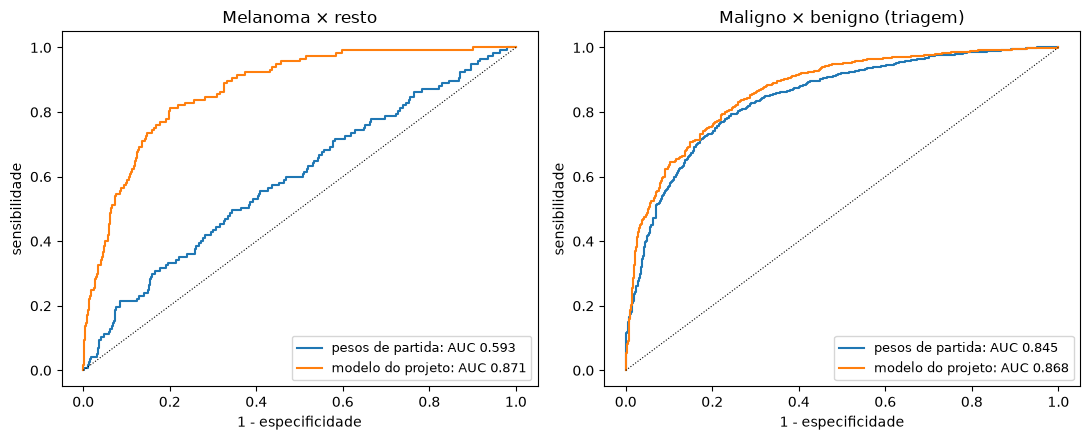

,sensibilidade,especificidade,melanomas perdidos,benignos encaminhados
limiar,,,,
0.287,0.966,0.412,15,341
0.400,0.941,0.540,23,267
0.500,0.907,0.617,33,222
0.600,0.869,0.690,43,180
0.700,0.802,0.764,57,137


In [18]:
from sklearn.metrics import roc_curve

prev = pd.read_csv(PASTA_MODELO / "previsoes_celular.csv")
y_cel = prev["dx"].map(CLASS_IDX).values
P_cel = {"pesos de partida": prev[[f"antes_p_{c}" for c in CLASSES]].values,
         "modelo do projeto": prev[[f"depois_p_{c}" for c in CLASSES]].values}
mel_cel = y_cel == CLASS_IDX["mel"]
mal_cel = np.isin(y_cel, MALIGNANT_8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for nome, p in P_cel.items():
    for ax, (alvo, score, titulo) in zip(axes, [(mel_cel, p[:, CLASS_IDX["mel"]], "Melanoma × resto"),
                                               (mal_cel, p[:, MALIGNANT_8].sum(1), "Maligno × benigno (triagem)")]):
        fpr, tpr, _ = roc_curve(alvo, score)
        ax.plot(fpr, tpr, label=f"{nome}: AUC {roc_auc_score(alvo, score):.3f}")
        ax.set(xlabel="1 - especificidade", ylabel="sensibilidade", title=titulo)
for ax in axes:
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# Triagem: o limiar escolhido na validação (dermatoscopia) fica agressivo no celular; a tabela
# mostra a troca sensibilidade × especificidade, que quem usa pode escolher
score_cel = P_cel["modelo do projeto"][:, MALIGNANT_8].sum(1)
linhas = []
for thr_ in [LIMIAR_MALIGNO, 0.4, 0.5, 0.6, 0.7]:
    enc = score_cel >= thr_
    linhas.append({"limiar": thr_, "sensibilidade": enc[mal_cel].mean(), "especificidade": (~enc[~mal_cel]).mean(),
                   "melanomas perdidos": int((mel_cel & ~enc).sum()), "benignos encaminhados": int((~mal_cel & enc).sum())})
pd.DataFrame(linhas).set_index("limiar").round(3)

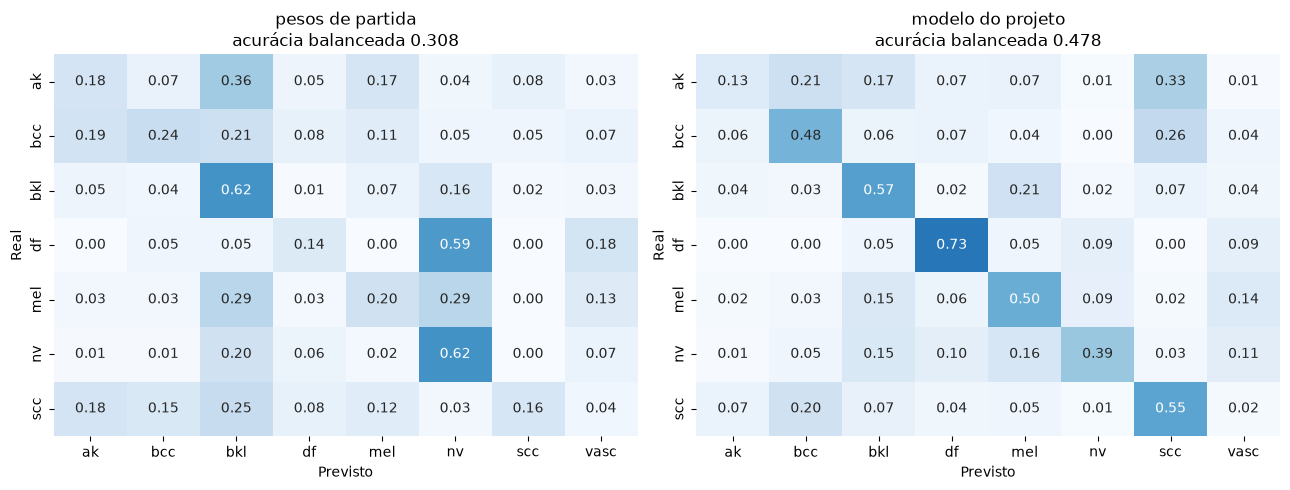

              precision    recall  f1-score   support

          ak      0.541     0.133     0.213       747
         bcc      0.663     0.477     0.555       959
         bkl      0.359     0.567     0.440       261
          df      0.088     0.727     0.158        22
         mel      0.224     0.504     0.311       117
          nv      0.806     0.391     0.526       297
         scc      0.200     0.550     0.294       240

   micro avg      0.406     0.389     0.397      2643
   macro avg      0.412     0.478     0.356      2643
weighted avg      0.548     0.389     0.406      2643



In [19]:
# Matriz de confusão nas fotos de celular (decisão ajustada pelo prior do treino, tau escolhido na validação).
# O teste não tem lesão vascular, por isso a linha vasc fica de fora.
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")  # vasc não existe no teste


presentes = [i for i in range(len(CLASSES)) if (y_cel == i).any()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, p) in zip(axes, P_cel.items()):
    pred_cel = adjust(p).argmax(1)
    cm_cel = confusion_matrix(y_cel, pred_cel, labels=list(range(len(CLASSES))), normalize="true")[presentes]
    sns.heatmap(cm_cel, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASSES, yticklabels=[CLASSES[i] for i in presentes], ax=ax)
    ax.set(xlabel="Previsto", ylabel="Real",
           title=f"{nome}\nacurácia balanceada {balanced_accuracy_score(y_cel, pred_cel):.3f}")
plt.tight_layout()
plt.show()

pred_cel = adjust(P_cel["modelo do projeto"]).argmax(1)
print(classification_report(y_cel, pred_cel, labels=presentes, target_names=[CLASSES[i] for i in presentes],
                            digits=3, zero_division=0))

# Registro de iterações

## Iteração 1: EfficientNetV2-B0, 224 px, na CPU (07/11/2026)

*Hoje estes são só os pesos de partida do modelo do projeto (iteração 4).*

**Configuração**: EfficientNetV2-B0 pré-treinada no ImageNet + metadados (idade, sexo, região do corpo); imagens com Shades of Gray, 224 px; fase 1 de 2 épocas só com a cabeça; fase 2 com ajuste fino da rede inteira com BatchNormalization congeladas, AdamW (lr de pico 3e-4, weight decay 0,02), aquecimento + cosseno, até 20 épocas com parada antecipada (paciência 5), batch 32; ajuste de prior com tau escolhido na validação; TTA de 8 visões.

**Treino**: ~7 h na CPU, com duas interrupções por falta de memória (retomado do backup). A melhor época foi a 11ª do ajuste fino; a parada antecipada encerrou o treino na 18ª.

| Variante | Acurácia balanceada (val, 8 classes) | Acurácia (teste) | Acurácia balanceada (teste, 7 classes) | AUC maligno × benigno (teste) |
|---|---|---|---|---|
| Fase 1: rede congelada (baseline) | 51,9% | 67,1% | 47,7% | 0,867 |
| Fase 2: ajuste fino | 66,1% | 81,8% | 72,4% | 0,938 |
| **Fase 2 + TTA (final)** | **66,3%** | **82,2%** | **74,3%** | **0,943** |

**Comparação com dermatologistas** (mesmas 1.412 imagens do teste, Tschandl et al., *Nature Medicine* 2020):

| | Acurácia | Acurácia balanceada |
|---|---|---|
| Dermatologistas sem IA | 69,4% | 71,4% |
| Dermatologistas com a IA do estudo | 74,4% | 75,4% |
| IA do estudo | 78,2% | 77,7% |
| **Nosso professor** | **76,7%** | **74,1%** |

**Triagem maligno × benigno**: com o limiar escolhido na validação para 95% de sensibilidade, o teste teve **95,8% de sensibilidade** e 73,3% de especificidade.

**Observações**
- O ajuste fino é o que mais pesa: +27 pontos de acurácia balanceada no teste sobre o baseline de embeddings congelados. O TTA soma cerca de +2 pontos.
- O professor já supera a média dos dermatologistas sem apoio da IA, mas ainda fica abaixo da IA do estudo.
- **Ponto fraco: melanoma**, com só 50% de sensibilidade quando a lesão é classificada sozinha. 22% dos melanomas saem como nevo e 14% como bkl. Na triagem com limiar de 95%, quase todos os casos malignos são sinalizados, mas a classe exata do melanoma ainda erra muito. O `df` também é confundido com nevo (23%).
- **Overfitting**: depois da época 8, a perda de validação sobe enquanto a de treino cai até 0,13. A acurácia balanceada estabiliza em ~64–66%. Mais regularização deve ajudar.
- **Por origem**: na validação, as imagens do BCN são as mais difíceis (64,5% de acurácia, contra 85% no HAM), e o teste vem todo do HAM. O BCN tem mais melanomas e lesões atípicas.
- A validação tem 8 classes, separando `ak` e `scc`, e o teste tem 7, com `akiec` juntando as duas. Por isso a acurácia balanceada do teste é maior.

**Próximos passos**
1. **Resolução e rede maiores na GPU do Kaggle** (EfficientNetV2-S, 384 px; `kaggle_professor.ipynb`): o maior ganho esperado, principalmente em melanoma, que depende de detalhes finos.
2. **Regularização contra o overfitting**: Mixup/CutMix, stochastic depth, EMA dos pesos.
3. **Ensemble** de professores com arquiteturas diferentes.
4. **Pseudo-rótulos** nas 6.726 imagens sem rótulo, que depois alimentam o aluno.

## Iteração 2: ajuste para foto de celular com simulação (08/11/2026)

**Motivação**: o professor da iteração 1, avaliado em bases que não viu, mantém AUC de melanoma 0,91 em dermatoscopia nova (ISIC 2019 teste, MILK10k) mas cai para 0,59 em fotos de celular (PAD-UFES-20 + HIBA).

**Configuração**: ajuste fino do `professor_effv2b0` (BatchNormalization congeladas, AdamW lr 1e-4 com aquecimento + cosseno, batch 32, até 8 épocas, paciência 3; melhor época a 7ª) em 23.435 imagens sem celular: ISIC 2019 treino, ISIC 2020, MILK10k dermatoscopia e *close-up*, MED-NODE, MSKCC e anônimas da ISIC, com nevos limitados a 6.000. Augmentation do pipeline + **simulação de celular** (recorte da borda, afastamento, cor forte, balanço de branco, sombra, resolução, desfoque, ruído, JPEG). Validação só nas mesmas bases (6.285 imagens), tau 1,1 e limiar 0,287 escolhidos nela. Três variantes: A só dermatoscopia + simulação; **B dermatoscopia + fotos de câmera + simulação**; C igual a B sem simulação (controle). ~2,5 h cada na CPU.

**Teste em fotos de celular** (PAD-UFES-20 + HIBA inteiras, 2.643 fotos, 117 melanomas, nenhuma vista no treino):

| Modelo | AUC melanoma | Sens. melanoma | Precisão melanoma | Acurácia balanceada | Triagem sens. / espec. |
|---|---|---|---|---|---|
| Professor da iteração 1 | 0,593 | 22% | 7% | 30% | 92% / 49% |
| A: só dermatoscopia + simulação | 0,735 | 26% | 13% | 40% | 91% / 61% |
| **B: + fotos de câmera + simulação (salvo em `modelos/`)** | **0,871** | **50%** | **22%** | **48%** | 97% / 41% |
| C: igual a B, sem simulação (controle) | 0,827 | 47% | 26% | 46% | 96% / 49% |

**Observações**
- A simulação de celular ajuda (B × C: +0,044 de AUC de melanoma, +3 pontos de sensibilidade), mas a maior parte do ganho vem de incluir fotos clínicas comuns no treino: só dermatoscopia + simulação (A) recupera menos da metade do caminho.
- No PAD-UFES-20 o B chega a AUC 0,915 e 67% de sensibilidade de melanoma; na HIBA, 0,817 e 37%. Na dermatoscopia empata com o professor da iteração 1 (iteração 4).
- O limiar de triagem transferido da validação em dermatoscopia fica agressivo no celular: 97% de sensibilidade mas 41% de especificidade (6 em 10 benignos encaminhados). Com limiar 0,5 fica em 91% / 62%. Precisa ser calibrado em foto de celular, com um conjunto separado do teste.
- A acurácia simples segue baixa (39%) porque o teste é dominado por `ak` e `bcc` em pele fotoenvelhecida, com muita confusão `ak` ↔ `bkl` ↔ `scc`. 58 dos 117 melanomas ainda recebem outra classe (`bkl` 17, `vasc` 16, `nv` 10, `df` 7); o `vasc`, classe rara inflada pelo ajuste de prior, é suspeito.
- Para comparação, um ajuste fino **com** fotos de celular no treino (não incluído no repositório) chegou a AUC de melanoma 0,96 num teste menor (401 fotos): dado real de celular ainda vale mais do que simulá-lo.

**Próximos passos**
1. Juntar as duas coisas: receita B (fotos + simulação) e depois ajuste fino com as fotos de celular disponíveis, guardando uma parte só para teste.
2. Calibrar tau e limiar de triagem em foto de celular.
3. Mais fotos de celular rotuladas (MRA-MIDAS, DDI; SCIN para lesões inflamatórias) e atacar a confusão `ak`/`bkl`/`scc`.

*A iteração 3 (triagem de erupções e alergias) está em `triagem_alergias/triagem_alergias.ipynb`.*

## Iteração 4: um único modelo no projeto (09/11/2026)

**Decisão**: o modelo da iteração 2 passa a ser o único modelo de pintas do projeto, em todas as rotas. Os pesos da iteração 1 ficam só como ponto de partida para retreinar (`modelos/pintas/pesos_de_partida.keras`).

**Por quê**: faltava medir o modelo novo em dermatoscopia, e ele empata com o anterior, enquanto no celular ganha com folga.

| Teste | Métrica | Pesos de partida | Modelo do projeto | IC 95% da diferença |
|---|---|---|---|---|
| Dermatoscopia (ISIC 2018) | acurácia | 82,2% | **82,8%** | −1,1 a +2,3 pontos |
| Dermatoscopia (ISIC 2018) | acurácia balanceada | 74,3% | **75,0%** | −2,4 a +3,6 pontos |
| Dermatoscopia (ISIC 2018) | AUC maligno × benigno | 0,943 | **0,945** | −0,006 a +0,012 |
| Dermatoscopia (ISIC 2018) | sensibilidade de melanoma | 50% | **62%** | |
| Celular (PAD-UFES-20 + HIBA) | acurácia | 31,5% | **38,9%** | +5 a +9 pontos |
| Celular (PAD-UFES-20 + HIBA) | acurácia balanceada | 30,3% | **47,8%** | +14 a +21 pontos |
| Celular (PAD-UFES-20 + HIBA) | AUC de melanoma | 0,593 | **0,871** | +0,23 a +0,32 |
| Celular (PAD-UFES-20 + HIBA) | AUC maligno × benigno | 0,845 | **0,868** | +0,01 a +0,04 |

**Comparação com dermatologistas** (mesmas 1.412 imagens): nosso modelo faz 76,3% de acurácia e 75,0% de acurácia balanceada; dermatologistas sem IA, 69,4% e 71,4%; IA do estudo, 78,2% e 77,7%.

**O que mudou no projeto**
- `pipeline.simular_celular` agora é o código comum da simulação de celular, usado pelo script de treino e demonstrado na seção 2.
- Uma pasta só para o modelo: `modelos/pintas/`. O notebook não treina, carrega as previsões salvas e reavalia.
- `tau` 1,1, prior do novo treino e limiar 0,287 em toda a avaliação.

**Observações**
- O limiar 0,287 dá 95,8% de sensibilidade na validação e 91,5% no teste. Calibrar só em dermatoscopia não ajudou (0,314, 89,6% no teste); a queda vem da mudança de base.
- A comparação das variantes da iteração 2 usou o teste de celular, então os números de celular podem estar levemente otimistas.
- Na simulação, o fundo do efeito "afastar" sai como retângulo cinza de borda marcada e a borda artificial do dermatoscópio continua em 25% das imagens.

**Próximos passos**
1. **Decidir o limiar de triagem** em dermatoscopia, de preferência em um conjunto novo: 0,20 daria 94,8% de sensibilidade e 76,0% de especificidade neste teste, mas agora ele já foi visto.
2. **Corrigir a simulação** (fundo do "afastar", borda artificial) e retreinar.
3. Ajuste fino com fotos de celular reais, guardando uma parte só para teste.

## Iteração 5: foco só no modelo de pintas (09/11/2026)

**Decisão**: a triagem de erupções, alergias e queimaduras fica pausada para concentrar o trabalho nas pintas. Tudo dela, com notebook, redes, orientações, splits e relatórios, foi para `triagem_alergias/` e continua executável por lá. Este notebook e `modelos/` ficam só com o modelo de pintas. As métricas do modelo não mudam.
